<a href="https://colab.research.google.com/github/siva-balaji2007/CryptoCurrency-price-evaluation-model-CAT-2-/blob/main/CAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the Bitcoin dataset
df = pd.read_csv("coin_Bitcoin.csv")

# Display the first 5 rows
print("First 5 rows:")
display(df.head())

# Check the dataset size
print("Dataset shape:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())



First 5 rows:


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,1,Bitcoin,BTC,2013-04-29 23:59:59,147.488007,134.000000,134.444000,144.539993,0.0,1.603769e+09
1,2,Bitcoin,BTC,2013-04-30 23:59:59,146.929993,134.050003,144.000000,139.000000,0.0,1.542813e+09
2,3,Bitcoin,BTC,2013-05-01 23:59:59,139.889999,107.720001,139.000000,116.989998,0.0,1.298955e+09
3,4,Bitcoin,BTC,2013-05-02 23:59:59,125.599998,92.281898,116.379997,105.209999,0.0,1.168517e+09
4,5,Bitcoin,BTC,2013-05-03 23:59:59,108.127998,79.099998,106.250000,97.750000,0.0,1.085995e+09


Dataset shape: (2991, 10)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2991 entries, 0 to 2990
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   SNo        2991 non-null   int64  
 1   Name       2991 non-null   object 
 2   Symbol     2991 non-null   object 
 3   Date       2991 non-null   object 
 4   High       2991 non-null   float64
 5   Low        2991 non-null   float64
 6   Open       2991 non-null   float64
 7   Close      2991 non-null   float64
 8   Volume     2991 non-null   float64
 9   Marketcap  2991 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 233.8+ KB

Missing values in each column:
SNo          0
Name         0
Symbol       0
Date         0
High         0
Low          0
Open         0
Close        0
Volume       0
Marketcap    0
dtype: int64


In [7]:

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort records by date
df = df.sort_values("Date").reset_index(drop=True)

# Select the most recent 2000 records
data = df.tail(2000).copy().reset_index(drop=True)

# Display dataset details
print("Selected dataset shape:", data.shape)
print("Start date:", data["Date"].min())
print("End date:", data["Date"].max())

# Check whether dates are consecutive daily records
date_gaps = data["Date"].diff().dropna()
print("Number of non-daily gaps:",
      (date_gaps != pd.Timedelta(days=1)).sum())

# Display first 5 selected records
display(data.head())



Selected dataset shape: (2000, 10)
Start date: 2016-01-15 23:59:59
End date: 2021-07-06 23:59:59
Number of non-daily gaps: 0


,SNo,Name,Symbol,Date,High,Low,Open,Close,Volume,Marketcap
0,992,Bitcoin,BTC,2016-01-15 23:59:59,430.255005,364.330994,430.255005,364.330994,153351008.0,5.496598e+09
1,993,Bitcoin,BTC,2016-01-16 23:59:59,390.557007,354.914001,365.072998,387.536011,120352000.0,5.848064e+09
2,994,Bitcoin,BTC,2016-01-17 23:59:59,390.964996,380.092010,387.152008,382.299011,45319600.0,5.770478e+09
3,995,Bitcoin,BTC,2016-01-18 23:59:59,388.104004,376.665009,381.733002,387.167999,54403900.0,5.845656e+09
4,996,Bitcoin,BTC,2016-01-19 23:59:59,387.730011,378.971985,387.026001,380.148987,46819800.0,5.740934e+09


In [10]:

from sklearn.preprocessing import MinMaxScaler

# Select numerical features
features = ["High", "Low", "Open", "Close", "Volume", "Marketcap"]

# Handle missing values
data[features] = data[features].ffill().bfill()

# Check for missing values
print("Missing values after handling:")
print(data[features].isnull().sum())

# Normalize numerical features
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data[features])

print("\nOriginal data shape:", data[features].shape)
print("Normalized data shape:", scaled_data.shape)

# Display first 5 normalized rows
print("\nFirst 5 normalized rows:")
display(pd.DataFrame(scaled_data, columns=features).head())



Missing values after handling:
High         0
Low          0
Open         0
Close        0
Volume       0
Marketcap    0
dtype: int64

Original data shape: (2000, 6)
Normalized data shape: (2000, 6)

First 5 normalized rows:


,High,Low,Open,Close,Volume,Marketcap
0,0.000858,0.000152,0.001032,0.000000,0.000356,0.000000
1,0.000242,0.000000,0.000000,0.000368,0.000262,0.000298
2,0.000248,0.000407,0.000350,0.000285,0.000048,0.000232
3,0.000204,0.000352,0.000264,0.000362,0.000074,0.000296
4,0.000198,0.000389,0.000348,0.000251,0.000052,0.000207


In [12]:

# Create sequences using the previous 7 days
window_size = 7
X = []
y = []

# Close is the 4th feature (index 3)
close_index = features.index("Close")

for i in range(window_size, len(scaled_data)):
    # Previous 7 days of all numerical features
    X.append(scaled_data[i-window_size:i])

    # Next day's closing price
    y.append(scaled_data[i, close_index])

X = np.array(X)
y = np.array(y)

print("Input shape (X):", X.shape)
print("Target shape (y):", y.shape)
print("Window size:", window_size)
print("Features per day:", X.shape[2])
print("First target (normalized closing price):", y[0])



Input shape (X): (1993, 7, 6)
Target shape (y): (1993,)
Window size: 7
Features per day: 6
First target (normalized closing price): 0.0002876348094018079


In [14]:

# Chronological 80/20 train-test split
split_index = int(len(X) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]

y_train = y[:split_index]
y_test = y[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


Training samples: 1594
Testing samples: 399
X_train shape: (1594, 7, 6)
X_test shape: (399, 7, 6)
y_train shape: (1594,)
y_test shape: (399,)


In [16]:

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Select numerical features
features = ["High", "Low", "Open", "Close", "Volume", "Marketcap"]
window_size = 7
close_index = features.index("Close")

# Use chronological 80/20 split on the original 2000 daily records
split_row = int(len(data) * 0.8)

train_data = data[features].iloc[:split_row].copy()
test_data = data[features].iloc[split_row:].copy()

# Fit scaler ONLY on training data
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train_data)

# Transform test data using the same scaler
test_scaled = scaler.transform(test_data)

# Combine scaled values to create windows across the boundary
scaled_all = np.vstack([train_scaled, test_scaled])

X, y = [], []

for i in range(window_size, len(scaled_all)):
    X.append(scaled_all[i-window_size:i])
    y.append(scaled_all[i, close_index])

X = np.array(X)
y = np.array(y)

# Split sequences at the original chronological boundary
split_index = split_row - window_size

X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input shape:", X_train.shape)
print("Test input shape:", X_test.shape)


Training samples: 1593
Testing samples: 400
Input shape: (1593, 7, 6)
Test input shape: (400, 7, 6)


In [19]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Make results more reproducible
tf.random.set_seed(42)
np.random.seed(42)

# Build the LSTM model
model = Sequential([
    LSTM(50, input_shape=(7, 6)),
    Dropout(0.2),
    Dense(25, activation="relu"),
    Dense(1)
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

# Display model architecture
model.summary()

# Stop early if validation loss stops improving
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 50)             │        11,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,701 (49.61 KB)

 Trainable params: 12,701 (49.61 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0046 - val_loss: 0.0056
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0035 - val_loss: 0.0017
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0047 - val_loss: 8.7070e-04
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0019 - val_loss: 0.0015
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014 - val_loss: 0.0016
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014 - val_loss: 0.0016
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0018 - val_loss: 0.0033
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - val_loss: 0.0017
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0020 - val_loss: 0.0049
Epoch 10/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0013 - val_loss: 0.0014
Epoch 11/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0021 - val_loss: 0.0036
Epoch 12/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - v

In [22]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict normalized closing prices on unseen test data
y_pred_scaled = model.predict(X_test)

# Convert normalized predictions back to actual Bitcoin prices
close_min = scaler.data_min_[close_index]
close_scale = scaler.data_range_[close_index]

y_test_actual = y_test * close_scale + close_min
y_pred_actual = y_pred_scaled.flatten() * close_scale + close_min

# Calculate evaluation metrics
mae = mean_absolute_error(y_test_actual, y_pred_actual)
rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))

print("Mean Absolute Error (MAE):", round(mae, 2), "USD")
print("Root Mean Squared Error (RMSE):", round(rmse, 2), "USD")


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Mean Absolute Error (MAE): 9065.91 USD
Root Mean Squared Error (RMSE): 13437.49 USD


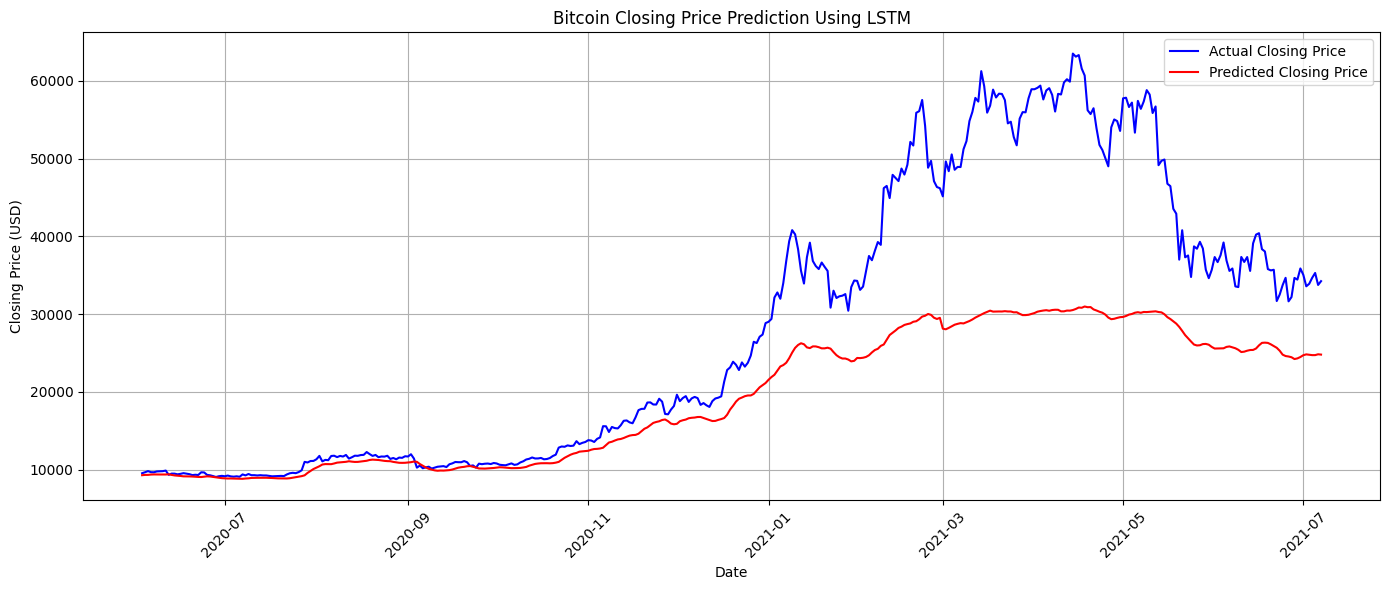

In [23]:

import matplotlib.pyplot as plt

# Get the dates corresponding to the test predictions
test_dates = data["Date"].iloc[split_row:].reset_index(drop=True)

# Plot actual and predicted closing prices
plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    y_test_actual,
    label="Actual Closing Price",
    color="blue"
)

plt.plot(
    test_dates,
    y_pred_actual,
    label="Predicted Closing Price",
    color="red"
)

plt.title("Bitcoin Closing Price Prediction Using LSTM")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

